In [ ]:
# Task: Descriptive Analysis

# Calculate basic statistical measures (mean, median, standard deviation, etc.) for numerical columns.
# Explore the distribution of categorical variables like "Country Code," "City," and"Cuisines." Identify the top cuisines and cities with the
# highest number of restaurants.

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
data = pd.read_csv("/home/vansh-kumar/cognifyz Task/Dataset .csv")
# data

print("\nDataset Shape:",data.shape)
print("\nFirst Five Rows:")
print(data.head())


Dataset Shape: (9551, 21)

First Five Rows:
   Restaurant ID         Restaurant Name  Country Code              City  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             Address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     Locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangr

In [33]:
# Numerical descriptive statisticsl

numeric_data = data.select_dtypes(include=np.number)

print("\nNumerical Summary:")
print(numeric_data.describe().round(2))



Numerical Summary:
       Restaurant ID  Country Code  Longitude  Latitude  Average Cost for two  \
count        9551.00       9551.00    9551.00   9551.00               9551.00   
mean      9051128.35         18.37      64.13     25.85               1199.21   
std       8791521.28         56.75      41.47     11.01              16121.18   
min            53.00          1.00    -157.95    -41.33                  0.00   
25%        301962.50          1.00      77.08     28.48                250.00   
50%       6004089.00          1.00      77.19     28.57                400.00   
75%      18352291.50          1.00      77.28     28.64                700.00   
max      18500652.00        216.00     174.83     55.98             800000.00   

       Price range  Aggregate rating     Votes  
count      9551.00           9551.00   9551.00  
mean          1.80              2.67    156.91  
std           0.91              1.52    430.17  
min           1.00              0.00      0.00  
25%  

In [34]:
# Calculate median seprately

print("\nMedian of Numerical Columns:")
print(numeric_data.median().round(2))


Median of Numerical Columns:
Restaurant ID           6004089.00
Country Code                  1.00
Longitude                    77.19
Latitude                     28.57
Average Cost for two        400.00
Price range                   2.00
Aggregate rating              3.20
Votes                        31.00
dtype: float64


In [35]:
print("\nStandard Deviation:")
print(numeric_data.std().round(2))


Standard Deviation:
Restaurant ID           8791521.28
Country Code                 56.75
Longitude                    41.47
Latitude                     11.01
Average Cost for two      16121.18
Price range                   0.91
Aggregate rating              1.52
Votes                       430.17
dtype: float64


In [36]:
# Categorical Analysis

categorical_columns = ["Country Code", "City", "Cuisines"]
for col in categorical_columns:
    print(f"Top 10 Values in {col}")
    
    print(data[col].value_counts(dropna=False).head(10))
    
    print("\nUnique values:", data[col].nunique(dropna=True))
    print("Missing Values:", data[col].isna().sum())

Top 10 Values in Country Code
Country Code
1      8652
216     434
215      80
30       60
214      60
189      60
148      40
208      34
14       24
162      22
Name: count, dtype: int64

Unique values: 15
Missing Values: 0
Top 10 Values in City
City
New Delhi       5473
Gurgaon         1118
Noida           1080
Faridabad        251
Ghaziabad         25
Ahmedabad         21
Amritsar          21
Bhubaneshwar      21
Guwahati          21
Lucknow           21
Name: count, dtype: int64

Unique values: 141
Missing Values: 0
Top 10 Values in Cuisines
Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: count, dtype: int64

Unique values: 1825
Missing Val


Top 15 individual cuisines:
Cuisines
North Indian    3960
Chinese         2735
Fast Food       1986
Mughlai          995
Italian          764
Bakery           745
Continental      736
Cafe             703
Desserts         653
South Indian     636
Street Food      562
American         390
Pizza            381
Mithai           380
Burger           251
Name: count, dtype: int64


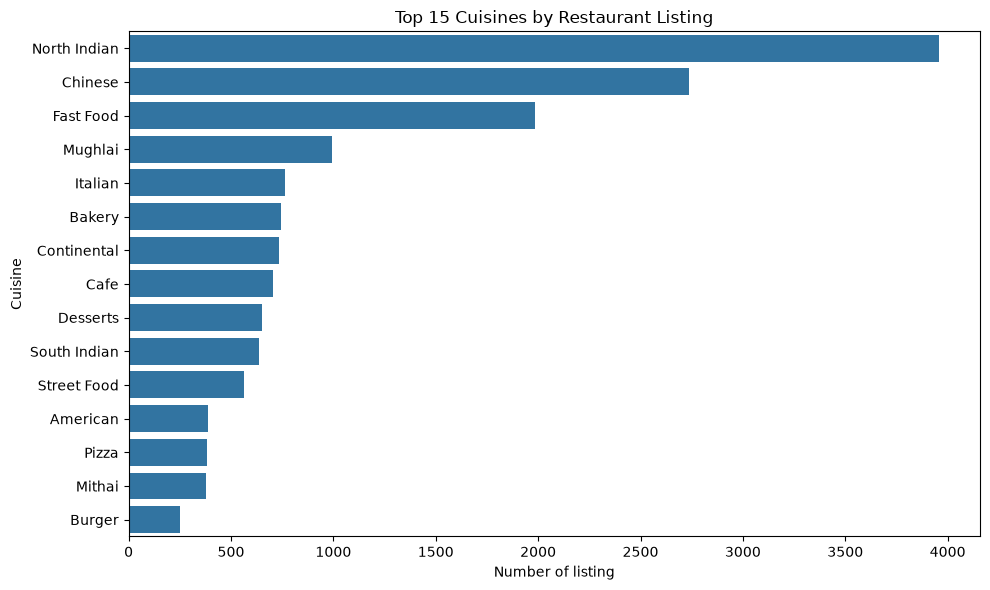

In [37]:
# Analyze individual cuisines

if "Cuisines" in data.columns:
    cuisines = (data["Cuisines"]
                .dropna()
                .astype(str)
                .str.split(",")
                .explode()
                .str.strip())
    
    cuisines = cuisines[cuisines.ne("")]
    top_cuisines = cuisines.value_counts().head(15)
    
    print("\nTop 15 individual cuisines:")
    print(top_cuisines)
    
    plt.figure(figsize=(10,6))
    sns.barplot(x=top_cuisines.values,
                y=top_cuisines.index)
    plt.title("Top 15 Cuisines by Restaurant Listing")
    plt.xlabel("Number of listing")
    plt.ylabel("Cuisine")
    plt.tight_layout()
    plt.show()

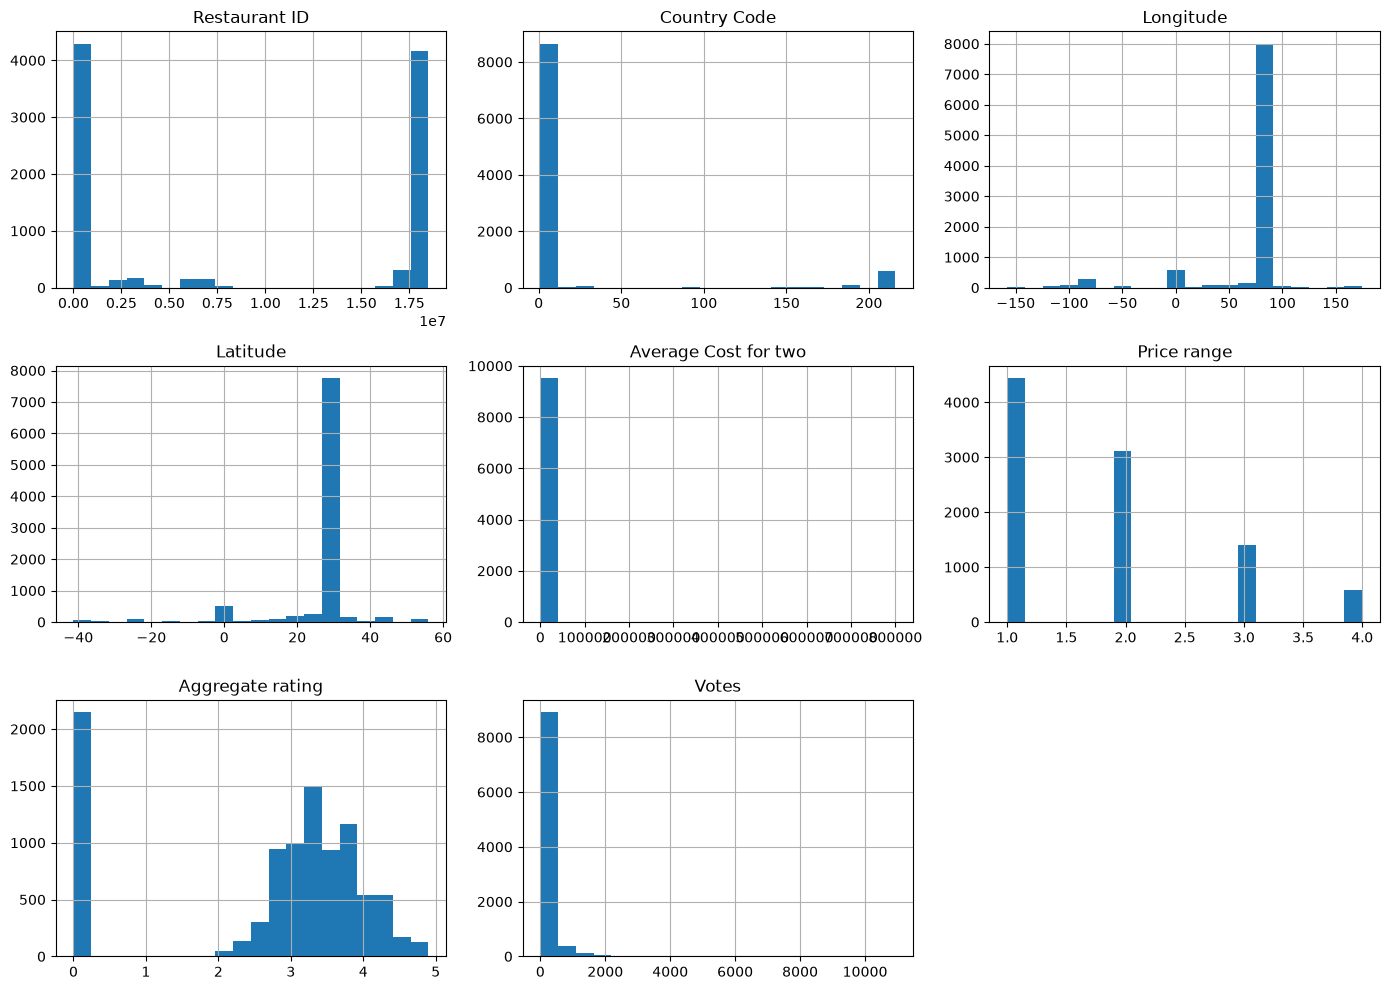

In [38]:
# Distribution of numerical columns

if not numeric_data.empty:
    numeric_data.hist(figsize=(14,10),bins=20)
    plt.title("Distribution of Numerical Variables")
    plt.tight_layout()
    plt.show()

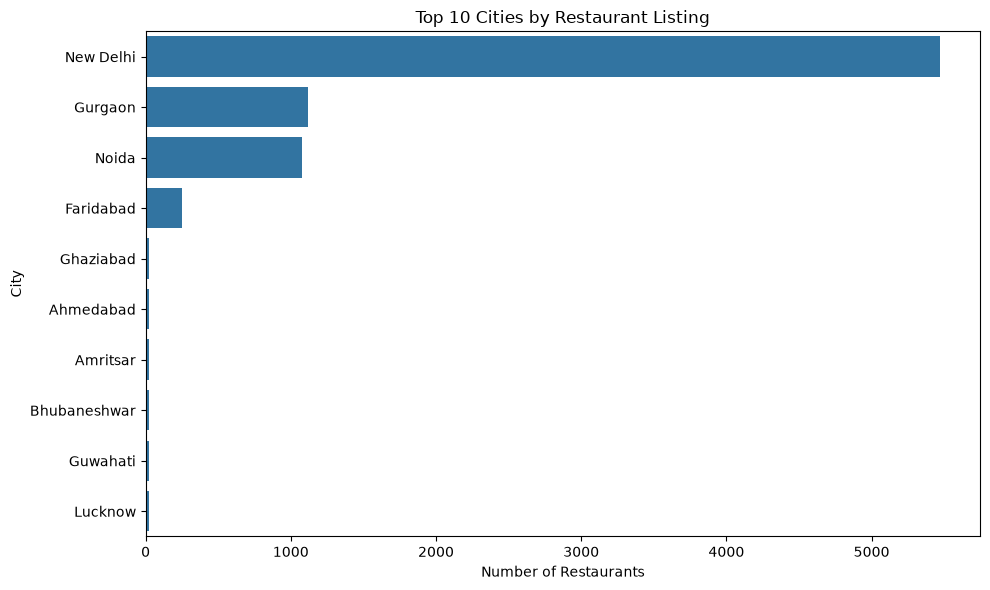

In [39]:
# Top 10 Cities

if "City" in data.columns:
    top_cities = data["City"].value_counts().head(10)
    
    plt.figure(figsize=(10,6))
    sns.barplot(x=top_cities.values,
                y=top_cities.index)
    
    plt.title("Top 10 Cities by Restaurant Listing")
    plt.xlabel("Number of Restaurants")
    plt.ylabel("City")
    plt.tight_layout()
    plt.show()

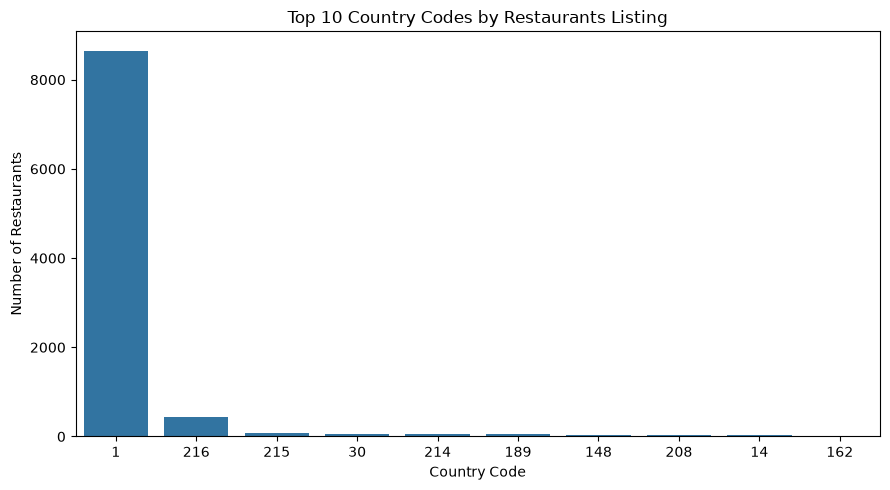

In [40]:
# Country Distribution
if "Country Code" in data.columns:
    country_code = data["Country Code"].value_counts().head(10)
    
    plt.figure(figsize=(9,5))
    sns.barplot(x=country_code.index.astype(str),
                y=country_code.values)
    
    plt.title("Top 10 Country Codes by Restaurants Listing")
    plt.xlabel("Country Code")
    plt.ylabel("Number of Restaurants")
    plt.tight_layout()
    plt.show()